# Wang et al. (2020): multiview Inception-v3 for ABUS lesion classification

**Paper.** Y. Wang, E. J. Choi, Y. Choi, H. Zhang, G. Y. Jin, S.-B. Ko. *Breast cancer classification in automated breast
ultrasound using multiview convolutional neural network with transfer learning.* Ultrasound in Medicine & Biology
46(5):1119-1132, 2020. [doi:10.1016/j.ultrasmedbio.2020.01.001](https://doi.org/10.1016/j.ultrasmedbio.2020.01.001)

**Method.** Crop 2D patches along the lesion's bounding box in the coronal and transverse views. *Multiview CNN A* stacks
coronal, transverse and transverse patches as the three image channels of one ImageNet Inception-v3, for every combination
of slices. *Multiview CNN B* gives each view its own Inception-v3. No lesion segmentation is needed, only a box.

**What we implement:** the Methods sections on patches, the modified Inception-v3 and multiview CNNs A and B, and the Results
in Table 2 (views) and part of Table 3 (CNN A from scratch). Code: `abus_classification/papers/wang2020/`. Not run: other backbones
(Table 3), PCA and HOG baselines (Table 4), and the observer study (Table 5), which needs radiologists.

**How this notebook runs.** Nothing here trains or tests a network. Results come from the Kaggle kernel
`wang2020-multiview`, stored in `../results/wang2020/`. Example lesions come through `tdsc_abus2023_pytorch`.

1. [Setup](#1-setup)
2. [Implementation details: paper vs ours](#2-implementation-details-paper-vs-ours)
3. [Architecture](#3-architecture)
4. [Verification](#4-verification)
5. [Data: what the network sees](#5-data-what-the-network-sees)
6. [Results (Kaggle)](#6-results-kaggle)
7. [Challenge benchmark](#7-challenge-benchmark)
8. [Protocol and how to re-run](#8-protocol-and-how-to-re-run)
9. [Open issues](#9-open-issues)

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from sklearn.metrics import roc_auc_score, roc_curve
from tdsc_abus2023_pytorch import TDSC, DataSplits
from abus_classification import challenge
from abus_classification.papers.wang2020 import WangCNN
from abus_classification.papers.wang2020.pipeline import MODES, lesion_patches, rotate_flip
from abus_classification.protocol import auc_ci, metrics

RESULTS, DATA_ROOT, SEEDS = Path("../results/wang2020"), Path("../data/tdsc"), (0, 1, 2)
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MALIGNANT, BENIGN, ACCENT, REFERENCE = "#eb6834", "#2a78d6", "#4a3aa7", "#a8a69f"
SEED_COLORS = ["#4a3aa7", "#008300", "#e87ba4"]
mpl.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "font.size": 10,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"], "text.color": INK,
    "axes.labelcolor": INK_2, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110})
def bare(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
def grid(ax, axis="y"):
    ax.grid(True, axis=axis, color=GRID); ax.set_axisbelow(True)
test_ds = TDSC(path=str(DATA_ROOT), split=DataSplits.TEST, download=False)
y = (test_ds.metadata["label"] == "M").to_numpy().astype(int)

## 2. Implementation details: paper vs ours

| | Paper | Ours |
|---|---|---|
| **Data** | Private: 316 lesions from 263 patients (135 malignant, 181 benign), Siemens ABVS | TDSC-ABUS 2023: 200 lesions, one per volume, GE Invenia |
| **Evaluation** | Five-fold CV, 3 folds to train, 1 to validate, 1 to test | Train (100) to fit, Validation (30) for early stopping, official Test (70) once |
| **Box** | Drawn by physicians, verified by a radiologist | Official TDSC bounding boxes |
| **Slices** | Several slices per lesion; choice not stated. About 3.7 patches per lesion in total | Two per view, at 1/3 and 2/3 of the box along the view's axis |
| **CNN A input** | Coronal, transverse, transverse as channels, all combinations; about 10 per lesion | Same, 2 x 2 x 2 = 8 per lesion |
| **CNN B input** | One backbone per view, grey copied to 3 channels; features joined at the first FC | Same; we join the two 2048-feature GAP vectors before FC 256 (assumed, the figure is the only source) |
| **Resize** | Input 299 x 299; how the box is resized is not stated | Plain resize of the box, ignoring aspect ratio, with anti-aliasing |
| **Backbone** | Keras Inception-v3, ImageNet, all layers fine-tuned | torchvision Inception-v3, ImageNet, all layers fine-tuned, no auxiliary head |
| **Head** | GAP, FC 256, 128, 2, softmax; dropout after the first two; Xavier uniform | Same; dropout rate not stated, 0.5 assumed; ReLU assumed |
| **Loss** | Not stated | Cross-entropy |
| **Optimiser** | Adadelta, batch 32 | Adadelta with PyTorch's default lr 1.0 (assumed), batch 32 |
| **Augmentation** | Fixed copies: rotations 90, 180, 270 and flips | Random rotation and flips per sample, per epoch |
| **Early stopping** | Validation AUC has not increased for 5 epochs | Same, keeping the best epoch; at most 50 epochs (assumed); validation AUC per lesion |
| **Lesion score** | Not stated | Mean probability over the lesion's patches |
| **Seeds** | One per fold | 3 seeds, reported per seed and as the mean of probabilities |

## 3. Architecture

CNN A on one lesion. CNN B replaces the stacked input with one backbone per view.

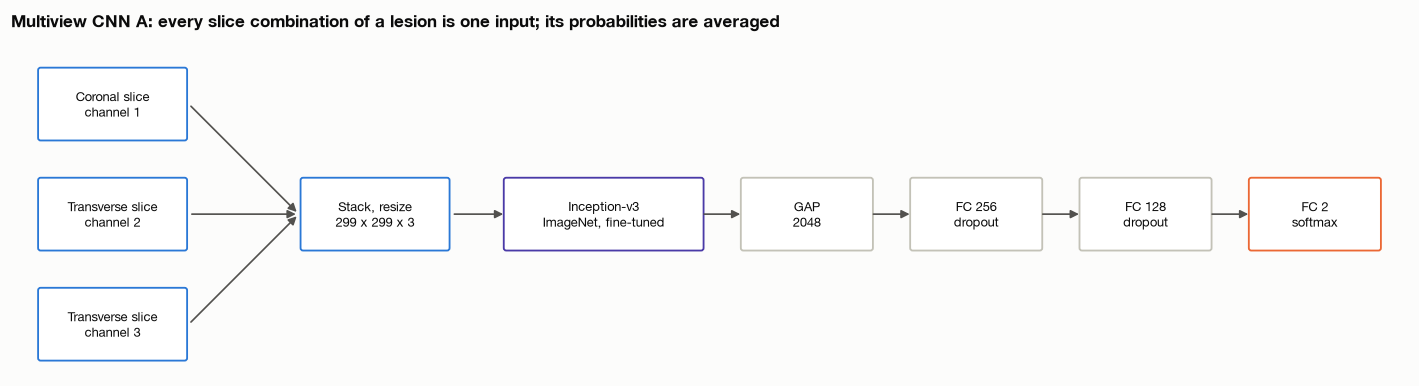

In [2]:
fig, ax = plt.subplots(figsize=(13, 3.9))
def box(x, y_, text, w=1.7, h=0.8, edge=AXIS, face="white"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y_ - h / 2), w, h, boxstyle="round,pad=0.03", fc=face, ec=edge, lw=1.2))
    ax.text(x, y_, text, ha="center", va="center", fontsize=8.5)
def arrow(a, b):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=11, color=INK_2, lw=1.1))
for yy, t in ((1.3, "Coronal slice\nchannel 1"), (0, "Transverse slice\nchannel 2"), (-1.3, "Transverse slice\nchannel 3")):
    box(0, yy, t, edge=BENIGN); arrow((0.9, yy), (2.2, 0))
box(3.1, 0, "Stack, resize\n299 x 299 x 3", edge=BENIGN)
items = [(5.8, "Inception-v3\nImageNet, fine-tuned", ACCENT), (8.2, "GAP\n2048", AXIS), (10.2, "FC 256\ndropout", AXIS), (12.2, "FC 128\ndropout", AXIS), (14.2, "FC 2\nsoftmax", MALIGNANT)]
last = 4.0
for x, t, e in items:
    w = 2.3 if x == 5.8 else 1.5
    arrow((last, 0), (x - w / 2, 0)); box(x, 0, t, w=w, edge=e); last = x + w / 2
ax.set_xlim(-1.2, 15.3); ax.set_ylim(-1.9, 2.1); ax.set_aspect("equal"); bare(ax)
ax.set_title("Multiview CNN A: every slice combination of a lesion is one input; its probabilities are averaged")
fig.tight_layout(); plt.show()

In [3]:
a, b = WangCNN(3, pretrained=False), WangCNN(6, pretrained=False)
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"CNN A: {count(a):,} parameters;  CNN B: {count(b):,} parameters;  shared head of CNN A: {count(a.fc):,}")
pd.DataFrame({m: {"inputs per lesion": len(k), "channels per input": len(k[0]), "backbones": len(k[0]) // 3} for m, k in MODES.items()}).T

CNN A: 22,343,266 parameters;  CNN B: 44,653,122 parameters;  shared head of CNN A: 557,698


,inputs per lesion,channels per input,backbones
cnn_a,8,3,1
cnn_b,4,6,2
coronal,2,3,1
transverse,2,3,1
cnn_a_scratch,8,3,1


## 4. Verification

Cheap checks on synthetic data, repeated in `test/papers_tests/test_wang2020.py`. Nothing here trains.

**Shapes and head.** One 299 x 299 input gives two logits, with the head the paper describes.

In [4]:
a.eval(); b.eval()
with torch.no_grad():
    assert a(torch.zeros(2, 3, 299, 299)).shape == (2, 2) and b(torch.zeros(2, 6, 299, 299)).shape == (2, 2)
widths = [m.out_features for m in a.fc if isinstance(m, torch.nn.Linear)]
assert widths == [256, 128, 2] and a.fc[0].in_features == 2048 and b.fc[0].in_features == 4096
print("head", widths, "  CNN A features", a.fc[0].in_features, "  CNN B features", b.fc[0].in_features)

head [256, 128, 2]   CNN A features 2048   CNN B features 4096


**Patches come from the right planes.** In a synthetic volume, one coronal plane holds 50 and one transverse plane holds 90.
With a box spanning 0-30, the first coronal slice (index 10) and the second transverse slice (index 20) must be those planes.

In [5]:
vol = np.zeros((10, 31, 31), np.uint8); vol[:, 10] = 50; vol[:, :, 20] = 90
p = lesion_patches(vol, ((0, 0, 0), (30, 30, 9)), size=8)
assert p[0].min() >= 50 and p[3].min() >= 90 and p[1].min() == 0 and p[2].min() == 0
print("minimum in coronal 1, coronal 2, transverse 1, transverse 2:", [int(x.min()) for x in p])

minimum in coronal 1, coronal 2, transverse 1, transverse 2: [50, 0, 0, 90]


**Combinations.** Coronal slices are indices 0 and 1, transverse 2 and 3. The paper's example gives CA-TA-TA, CA-TA-TB, CA-TB-TA and
CA-TB-TB for one coronal slice; with two coronal slices we get 8. **Augmentation** must move all channels together.

In [6]:
assert MODES["cnn_a"][:4] == [(0, 2, 2), (0, 2, 3), (0, 3, 2), (0, 3, 3)] and len(MODES["cnn_a"]) == 8
x = torch.arange(16.).reshape(4, 4).repeat(3, 3, 1, 1); out = rotate_flip(x)
assert all((s[0] == s[1]).all() and (s[0] == s[2]).all() for s in out)
print("CNN A, first coronal slice:", MODES["cnn_a"][:4], "  augmentation keeps channels aligned")

CNN A, first coronal slice: [(0, 2, 2), (0, 2, 3), (0, 3, 2), (0, 3, 3)]   augmentation keeps channels aligned


## 5. Data: what the network sees

Two test lesions, one malignant and one benign: the official box on the full scan, the two views' patches at 299 x 299, and one stacked
CNN A input shown in colour (red coronal, green and blue transverse). The plain resize makes every box square, so a lesion's height-to-width
ratio does not reach the network.

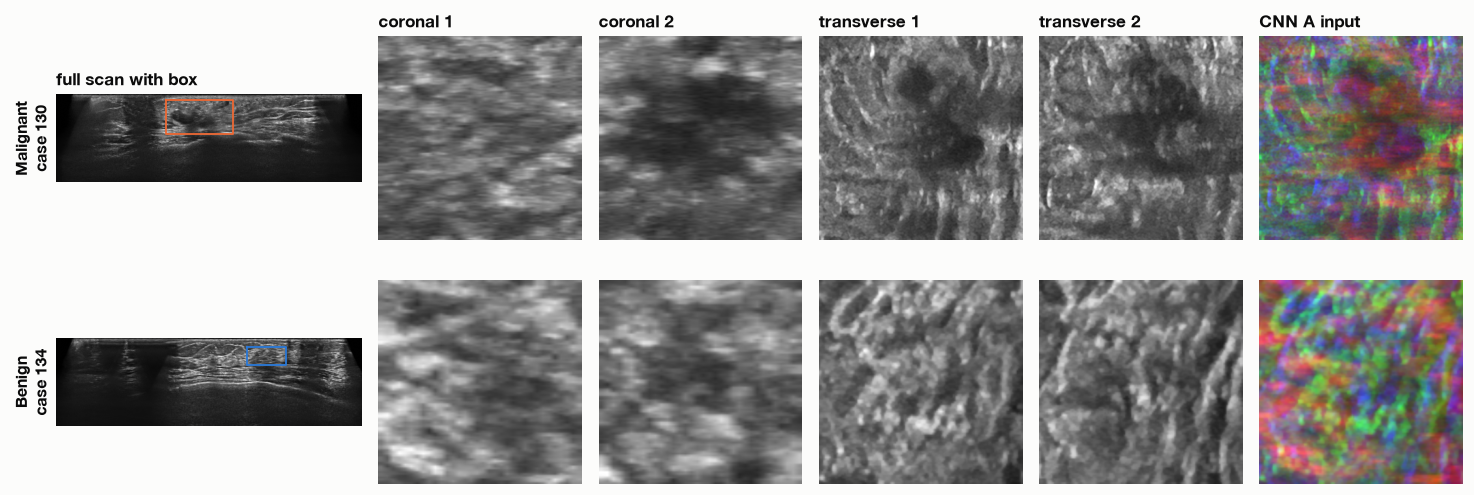

In [7]:
meta = test_ds.metadata
picks = {"M": int(np.flatnonzero(meta.label == "M")[0]), "B": int(np.flatnonzero(meta.label == "B")[0])}
fig, axes = plt.subplots(2, 6, figsize=(13.5, 5), gridspec_kw={"width_ratios": [1.5, 1, 1, 1, 1, 1]})
for row, (lab, i) in enumerate(picks.items()):
    vol, _, _, bx = test_ds[i]
    (x0, y0, z0), (x1, y1, z1) = [[int(v) for v in k] for k in bx]
    patches = lesion_patches(vol, bx)
    ax = axes[row, 0]; ax.imshow(vol[:, :, (x0 + x1) // 2].T, cmap="gray", aspect=0.073 / 0.2)   # rows 0.073 mm, columns 0.2 mm
    color = MALIGNANT if lab == "M" else BENIGN
    ax.plot([z0, z1, z1, z0, z0], [y0, y0, y1, y1, y0], color=color, lw=1.2); bare(ax)
    ax.set_ylabel(f"{'Malignant' if lab == 'M' else 'Benign'}\ncase {meta.index[i]}", fontsize=10.5, weight="bold", color=INK)
    names = ["coronal 1", "coronal 2", "transverse 1", "transverse 2"]
    for k in range(4):
        axes[row, k + 1].imshow(patches[k], cmap="gray", vmin=0, vmax=255); bare(axes[row, k + 1]); axes[row, k + 1].set_title(names[k] if row == 0 else "")
    axes[row, 5].imshow(np.stack([patches[0], patches[2], patches[3]], -1)); bare(axes[row, 5]); axes[row, 5].set_title("CNN A input" if row == 0 else "")
    if row == 0: ax.set_title("full scan with box")
fig.tight_layout(); plt.show()

## 6. Results (Kaggle)

Loaded from `../results/wang2020/`: metrics, per-run test probabilities, and per-epoch training loss and validation AUC.

### 6.1 Paper vs ours (Tables 2 and 3)

The paper's numbers are the mean over five folds on its own data, so they are context, not a like-for-like target. The paper's text repeats the coronal numbers for
the transverse view; we use its Table 2 (0.832, 0.838, 0.9076).

In [8]:
NAMES = {"cnn_a": "CNN A", "cnn_b": "CNN B", "coronal": "Coronal only", "transverse": "Transverse only", "cnn_a_scratch": "CNN A, from scratch"}
PAPER = pd.DataFrame({"AUC": [0.9468, 0.9346, 0.8874, 0.9076, 0.9043], "Sens": [0.886, 0.865, 0.831, 0.832, 0.822], "Spec": [0.876, 0.848, 0.800, 0.838, 0.859]}, index=list(NAMES.values()))
stored = pd.read_csv(RESULTS / "wang2020_results.csv", index_col=0)
probs = {m: {s: np.load(RESULTS / f"wang2020_{m}_seed{s}.npz")["prob"] for s in SEEDS} for m in NAMES}
rows = {}
for m, name in NAMES.items():
    ens = np.mean(list(probs[m].values()), 0)
    assert np.allclose(list(metrics(y, ens).values()), stored.loc[f"{m} mean of seeds"].values, atol=1e-4)   # labels line up with Kaggle
    seed_auc = [roc_auc_score(y, p) for p in probs[m].values()]; lo, hi = auc_ci(y, ens); r = metrics(y, ens)
    rows[name] = {"paper AUC": PAPER.AUC[name], "ours AUC (mean of seeds)": r["AUC"], "95% CI": f"{lo:.2f}-{hi:.2f}", "seed AUCs": " ".join(f"{a:.3f}" for a in seed_auc), "seed sd": np.std(seed_auc, ddof=1),
                  "paper Sens": PAPER.Sens[name], "ours Sens": r["Sens"], "paper Spec": PAPER.Spec[name], "ours Spec": r["Spec"], "ours Acc": r["Acc"]}
table = pd.DataFrame(rows).T
table

,paper AUC,ours AUC (mean of seeds),95% CI,seed AUCs,seed sd,paper Sens,ours Sens,paper Spec,ours Spec,ours Acc
CNN A,0.9468,0.755,0.63-0.86,0.739 0.728 0.759,0.015642,0.886,0.675,0.876,0.633333,0.657143
CNN B,0.9346,0.739167,0.61-0.86,0.793 0.757 0.590,0.108372,0.865,1.0,0.848,0.0,0.571429
Coronal only,0.8874,0.724167,0.58-0.85,0.735 0.710 0.736,0.01468,0.831,1.0,0.8,0.0,0.571429
Transverse only,0.9076,0.804167,0.69-0.90,0.770 0.784 0.758,0.012937,0.832,0.975,0.838,0.366667,0.714286
"CNN A, from scratch",0.9043,0.778333,0.64-0.89,0.731 0.780 0.772,0.026313,0.822,1.0,0.859,0.233333,0.671429


In [9]:
print(stored.round(3).to_string())

                               AUC    Acc   Prec   Sens   Spec     F1
cnn_a seed 0                 0.739  0.686  0.737  0.700  0.667  0.718
cnn_a seed 1                 0.728  0.457  0.750  0.075  0.967  0.136
cnn_a seed 2                 0.759  0.671  0.689  0.775  0.533  0.729
cnn_a mean of seeds          0.755  0.657  0.710  0.675  0.633  0.692
cnn_b seed 0                 0.793  0.771  0.740  0.925  0.567  0.822
cnn_b seed 1                 0.757  0.571  0.571  1.000  0.000  0.727
cnn_b seed 2                 0.590  0.571  0.571  1.000  0.000  0.727
cnn_b mean of seeds          0.739  0.571  0.571  1.000  0.000  0.727
coronal seed 0               0.735  0.571  0.571  1.000  0.000  0.727
coronal seed 1               0.710  0.571  0.571  1.000  0.000  0.727
coronal seed 2               0.736  0.571  0.571  1.000  0.000  0.727
coronal mean of seeds        0.724  0.571  0.571  1.000  0.000  0.727
transverse seed 0            0.770  0.686  0.650  0.975  0.300  0.780
transverse seed 1   

### 6.2 ROC and predicted probabilities

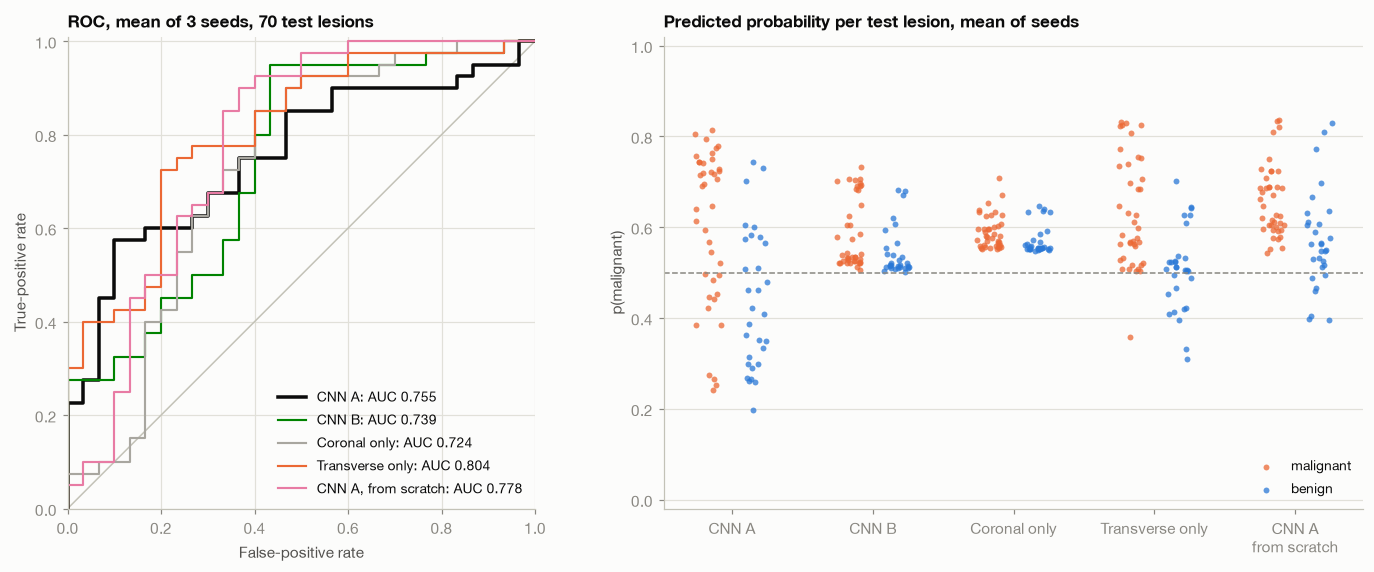

In [10]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.3), gridspec_kw={"width_ratios": [1, 1.25]})
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
for (m, name), col in zip(NAMES.items(), ["#0b0b0b", "#008300", "#a8a69f", "#eb6834", "#e87ba4"]):
    e = np.mean(list(probs[m].values()), 0); f, t, _ = roc_curve(y, e)
    ax.plot(f, t, color=col, lw=2.3 if m == "cnn_a" else 1.4, label=f"{name}: AUC {roc_auc_score(y, e):.3f}")
ax.set_aspect("equal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
grid(ax, "both"); ax.legend(loc="lower right"); ax.set_title("ROC, mean of 3 seeds, 70 test lesions")
rng = np.random.default_rng(0)
for k, m in enumerate(NAMES):
    e = np.mean(list(probs[m].values()), 0)
    for lab, col, off in ((1, MALIGNANT, -0.17), (0, BENIGN, 0.17)):
        ax2.scatter(k + off + rng.uniform(-.09, .09, (y == lab).sum()), e[y == lab], s=15, color=col, alpha=.75, lw=0, label=("malignant" if lab else "benign") if k == 0 else None)
ax2.axhline(.5, color=MUTED, ls="--", lw=1); ax2.set_xticks(range(5), [n.replace(", ", "\n") for n in NAMES.values()]); ax2.set_ylim(-.02, 1.02); ax2.set_ylabel("p(malignant)")
grid(ax2); ax2.legend(loc="lower right"); ax2.set_title("Predicted probability per test lesion, mean of seeds")
fig.tight_layout(); plt.show()

### 6.3 Training curves and the validation-test gap

Early stopping keeps the epoch with the best AUC on 30 validation lesions. The last chart compares that best validation AUC with the test AUC of the same model.

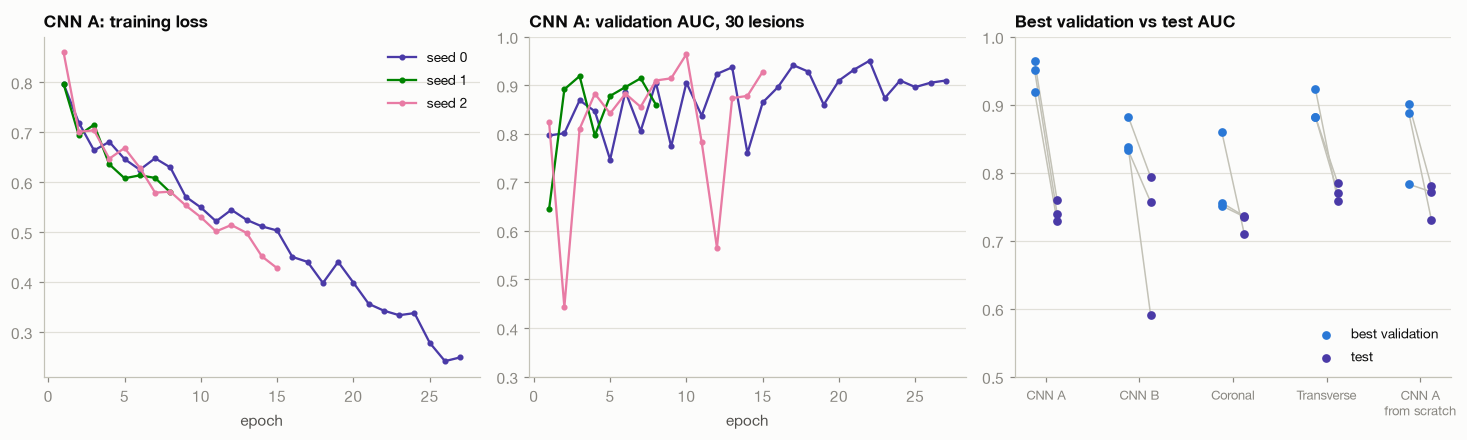

                       val   test    gap
model                                   
CNN A                0.944  0.742  0.202
CNN B                0.851  0.713  0.137
Coronal only         0.789  0.727  0.062
Transverse only      0.896  0.771  0.125
CNN A, from scratch  0.857  0.761  0.096

validation: 17 malignant, 13 benign


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1))
for s, col in zip(SEEDS, SEED_COLORS):
    h = pd.read_csv(RESULTS / f"wang2020_cnn_a_seed{s}_history.csv")
    axes[0].plot(h.epoch, h.loss, "o-", ms=3, color=col, label=f"seed {s}"); axes[1].plot(h.epoch, h.val_auc, "o-", ms=3, color=col)
axes[0].set_title("CNN A: training loss"); axes[0].legend(); axes[1].set_title("CNN A: validation AUC, 30 lesions"); axes[1].set_ylim(.3, 1)
for a_ in axes[:2]: a_.set_xlabel("epoch"); grid(a_)
ax = axes[2]; gap = []
for k, (m, name) in enumerate(NAMES.items()):
    for s in SEEDS:
        v, t = float(np.load(RESULTS / f"wang2020_{m}_seed{s}.npz")["val_auc"]), roc_auc_score(y, probs[m][s]); gap.append((name, s, v, t))
        ax.plot([k - .12, k + .12], [v, t], color=AXIS, lw=1, zorder=1); ax.scatter(k - .12, v, s=22, color=BENIGN, zorder=2, label="best validation" if not k and not s else None); ax.scatter(k + .12, t, s=22, color=ACCENT, zorder=2, label="test" if not k and not s else None)
ax.set_xticks(range(5), [n.replace(", ", "\n").replace(" only", "") for n in NAMES.values()], fontsize=8.5); ax.set_ylim(.5, 1); grid(ax); ax.legend(loc="lower right"); ax.set_title("Best validation vs test AUC")
fig.tight_layout(); plt.show()
gap = pd.DataFrame(gap, columns=["model", "seed", "val", "test"]); gap["gap"] = gap.val - gap.test
print(gap.groupby("model", sort=False)[["val", "test", "gap"]].mean().round(3).to_string())
val_y = TDSC(path=str(DATA_ROOT), split=DataSplits.VALIDATION, download=False).metadata.label
print("\nvalidation:", (val_y == "M").sum(), "malignant,", (val_y == "B").sum(), "benign")

## 7. Challenge benchmark

The TDSC-ABUS 2023 evaluation (`abus_classification/challenge.py`, explained in `challenge-benchmark.ipynb`), placed on the published leaderboard, using the mean of 3 seeds.
**Classification only:** this method only classifies. It also uses the official ground-truth boxes, which challenge teams did not have.

In [12]:
board = challenge.benchmark({name: challenge.classification(y, np.mean(list(probs[m].values()), 0)) for m, name in NAMES.items()})
board[["ACC", "AUC", "Cls_Score", "Cls_Rank"]].round(3)

,ACC,AUC,Cls_Score,Cls_Rank
CNN A,0.657,0.755,0.558,5/9
CNN B,0.571,0.739,0.333,6/9
Coronal only,0.571,0.724,0.310,6/9
Transverse only,0.714,0.804,0.768,3/9
"CNN A, from scratch",0.671,0.778,0.628,5/9


## 8. Protocol and how to re-run

- **Data:** TDSC-ABUS 2023 through `tdsc_abus2023_pytorch`. Fit on Train (100), stop early on Validation (30), report once on the official Test split (70). Malignant is positive. This departs from the
  usual training on all 130, because the paper's early stopping needs lesions kept out of training.
- **Seeds:** 3 (0, 1, 2), per seed and as the mean of probabilities; AUC 95% CI by bootstrap over test lesions.
- **Re-run on Kaggle** (GPU, about 50 minutes for all 15 runs). `kaggle/wang2020/run.py` clones `feat/wang2020`; a finished run with its `.npz` present is not trained again.

```bash
python kaggle/push.py wang2020
```

```bash
kaggle kernels output mralinp/wang2020-multiview -p results/wang2020
```

- **Stored results:** `results/wang2020/` holds metrics, test probabilities and histories. The checkpoints and patch cache stay in the Kaggle kernel output.

## 9. Open issues

1. **AUC is far below the paper:** 0.755 for CNN A against 0.9468, and the paper's value is above our 95% CI (0.63-0.86). The data, scanner, evaluation and number of training lesions (100 against about 190) all differ.
2. **The multiview gain does not reproduce.** The transverse view alone scores highest (0.804), then CNN A from scratch (0.778), CNN A (0.755), CNN B (0.739) and coronal (0.724). All CIs overlap, so we cannot claim a reversed order, only that the paper's gain from multiview and from ImageNet weights is not visible here.
3. **Validation is far above test.** The best validation AUC of CNN A averages 0.94 and its test AUC 0.74 on the same models; the other configurations show smaller gaps (0.06-0.14). Hypotheses, none tested:
   - *Selection on few lesions:* the best epoch out of many on 30 lesions is optimistic, and noisy.
   - *Unlucky or easier split:* 30 lesions may simply be easier than these 70. The curves also move a lot from epoch to epoch.
4. **Unstable threshold.** Several runs call nearly every lesion malignant (specificity 0.0), while CNN A seed 1 calls almost none (sensitivity 0.075). AUC is less affected. Choosing the threshold on validation may help accuracy-type metrics.
5. **Training looks unstable.** Coronal-only loss stays near 0.7 and its runs stop after 8-12 epochs, so it may not train properly at Adadelta's lr of 1.0. That rate is our assumption.
6. **Aspect ratio is lost.** Resizing every box to a square removes a known malignancy clue. Square crops in millimetres are the cheapest next test.
7. **Not run:** other backbones, PCA and HOG baselines, and the observer study.